<a href="https://colab.research.google.com/github/N125-ui/GOOGLE-COLAB/blob/main/Zeravia_mini.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**SECTION 1: PROBLEM SETUP & CLIENT GOALS**

In [ ]:
# Business Context: A retail client wants to analyze customer shopping trends to
# understand purchasing behavior, predict total transaction spend (Regression),
# and identify high-value sales (Classification) to optimize targeted marketing.

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix, mean_absolute_error, mean_squared_error, r2_score,
)
from sklearn.model_selection import train_test_split

print("--- SECTION 1: Environment & Libraries Setup Complete ---")

--- SECTION 1: Environment & Libraries Setup Complete ---


**SECTION 2: PYTHON FUNDAMENTALS**

In [ ]:
# Demonstrating basic Python data structures and mapping functions
category_discount_map = {
    "Beauty": 0.05,  # 5% promotional discount
    "Clothing": 0.10,  # 10% promotional discount
    "Electronics": 0.15,  # 15% promotional discount
}

def calculate_discounted_price(amount, category):
  """Calculates estimated price after applying category promotional discount."""
  discount_rate = category_discount_map.get(category, 0.0)
  return amount * (1 - discount_rate)

print(
    "Sample Category Discount Mapping:",
    calculate_discounted_price(100, "Electronics"),
)

Sample Category Discount Mapping: 85.0


**SECTION 3: DATA LOADING**

In [ ]:
# Load dataset (if running locally, ensure retail_sales_dataset.csv is in your folder)
try:
  df = pd.read_csv("retail_sales_dataset-selected-columns.csv")
  print("\nLoaded 'retail_sales_dataset.csv' successfully.")
except FileNotFoundError:
  print(
      "\nLocal CSV file not found. Generating compliant Retail Sales dataset"
      " matching target structure..."
  )
  np.random.seed(42)
  n_rows = 1000
  df = pd.DataFrame({
      "Transaction ID": range(1, n_rows + 1),
      "Date": pd.date_range(start="2023-01-01", periods=n_rows, freq="h"),
      "Customer ID": [f"CUST{i:04d}" for i in range(1, n_rows + 1)],
      "Gender": np.random.choice(["Male", "Female"], size=n_rows),
      "Age": np.random.randint(18, 65, size=n_rows),
      "Product Category": np.random.choice(
          ["Beauty", "Clothing", "Electronics"], size=n_rows
      ),
      "Quantity": np.random.randint(1, 5, size=n_rows),
      "Price per Unit": np.random.choice([25, 50, 100, 200, 300], size=n_rows),
  })
  df["Total Amount"] = df["Quantity"] * df["Price per Unit"]

print(f"Dataset Shape: {df.shape}")
print("\nFirst 5 Rows:")
print(df.head())
print(df.dtypes)


Loaded 'retail_sales_dataset.csv' successfully.
Dataset Shape: (1000, 8)

First 5 Rows:
   Transaction ID Customer ID  Gender  Age Product Category  Quantity  \
0               1     CUST001    Male   34           Beauty         3   
1               2     CUST002  Female   26         Clothing         2   
2               3     CUST003    Male   50      Electronics         1   
3               4     CUST004    Male   37         Clothing         1   
4               5     CUST005    Male   30           Beauty         2   

   Price per Unit  Total Amount  
0              50           150  
1             500          1000  
2              30            30  
3             500           500  
4              50           100  
Transaction ID       int64
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object


**SECTION 4: NUMPY OPERATIONS & STATISTICAL ANALYSIS**

In [ ]:
age_array = df["Age"].to_numpy()
total_amount_array = df["Total Amount"].to_numpy()

print(f"Age - Mean: {np.mean(age_array):.2f}, Std Dev: {np.std(age_array):.2f}")
print(
    f"Age - Min: {np.min(age_array)}, Max: {np.max(age_array)}, Median:"
    f" {np.median(age_array)}"
)
print(
    f"Total Amount - Mean: ${np.mean(total_amount_array):.2f}, Median:"
    f" ${np.median(total_amount_array):.2f}"
)
print(
    f"Total Amount - Min: ${np.min(total_amount_array)}, Max:"
    f" ${np.max(total_amount_array)}"
)

Age - Mean: 41.39, Std Dev: 13.67
Age - Min: 18, Max: 64, Median: 42.0
Total Amount - Mean: $456.00, Median: $135.00
Total Amount - Min: $25, Max: $2000


**SECTION 5: DATA CLEANING & PREPROCESSING**

In [ ]:
print("Missing values before cleaning:\n", df.isnull().sum())

# Handle missing values if present (impute numeric with median, mode for categorical)
for col in df.select_dtypes(include=[np.number]).columns:
  df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object"]).columns:
  df[col] = df[col].fillna(df[col].mode()[0])

# Drop duplicates
df = df.drop_duplicates()

# Drop identifier columns irrelevant to modeling
df_cleaned = df.drop(
    columns=["Transaction ID", "Customer ID", "Date"], errors="ignore"
)
print("Cleaned Dataset Shape:", df_cleaned.shape)

Missing values before cleaning:
 Transaction ID      0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
Cleaned Dataset Shape: (1000, 6)


**SECTION 6: FEATURE ENGINEERING**

In [ ]:
# Define Binary Classification Target: High_Value_Sale (1 if Total Amount > $500, else 0)
df_cleaned["High_Value_Sale"] = (df_cleaned["Total Amount"] > 500).astype(int)

print(
    "Target Distribution (High_Value_Sale):\n",
    df_cleaned["High_Value_Sale"].value_counts(),
)

Target Distribution (High_Value_Sale):
 High_Value_Sale
0    701
1    299
Name: count, dtype: int64


**SECTION 7: EXPLORATORY DATA ANALYSIS (GROUPBY & AGGREGATIONS)**

In [ ]:
category_summary = (
    df_cleaned.groupby("Product Category")
    .agg(
        Average_Spend=("Total Amount", "mean"),
        Total_Revenue=("Total Amount", "sum"),
        Transaction_Count=("Total Amount", "count"),
    )
    .reset_index()
)
print(category_summary)

gender_summary = df_cleaned.groupby("Gender")["Total Amount"].mean()
print("\nAverage Total Spend by Gender:\n", gender_summary)

  Product Category  Average_Spend  Total_Revenue  Transaction_Count
0           Beauty     467.475570         143515                307
1         Clothing     443.247863         155580                351
2      Electronics     458.786550         156905                342

Average Total Spend by Gender:
 Gender
Female    456.549020
Male      455.428571
Name: Total Amount, dtype: float64


**SECTION 8: DATA VISUALIZATION**

/tmp/ipykernel_5360/1547954724.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


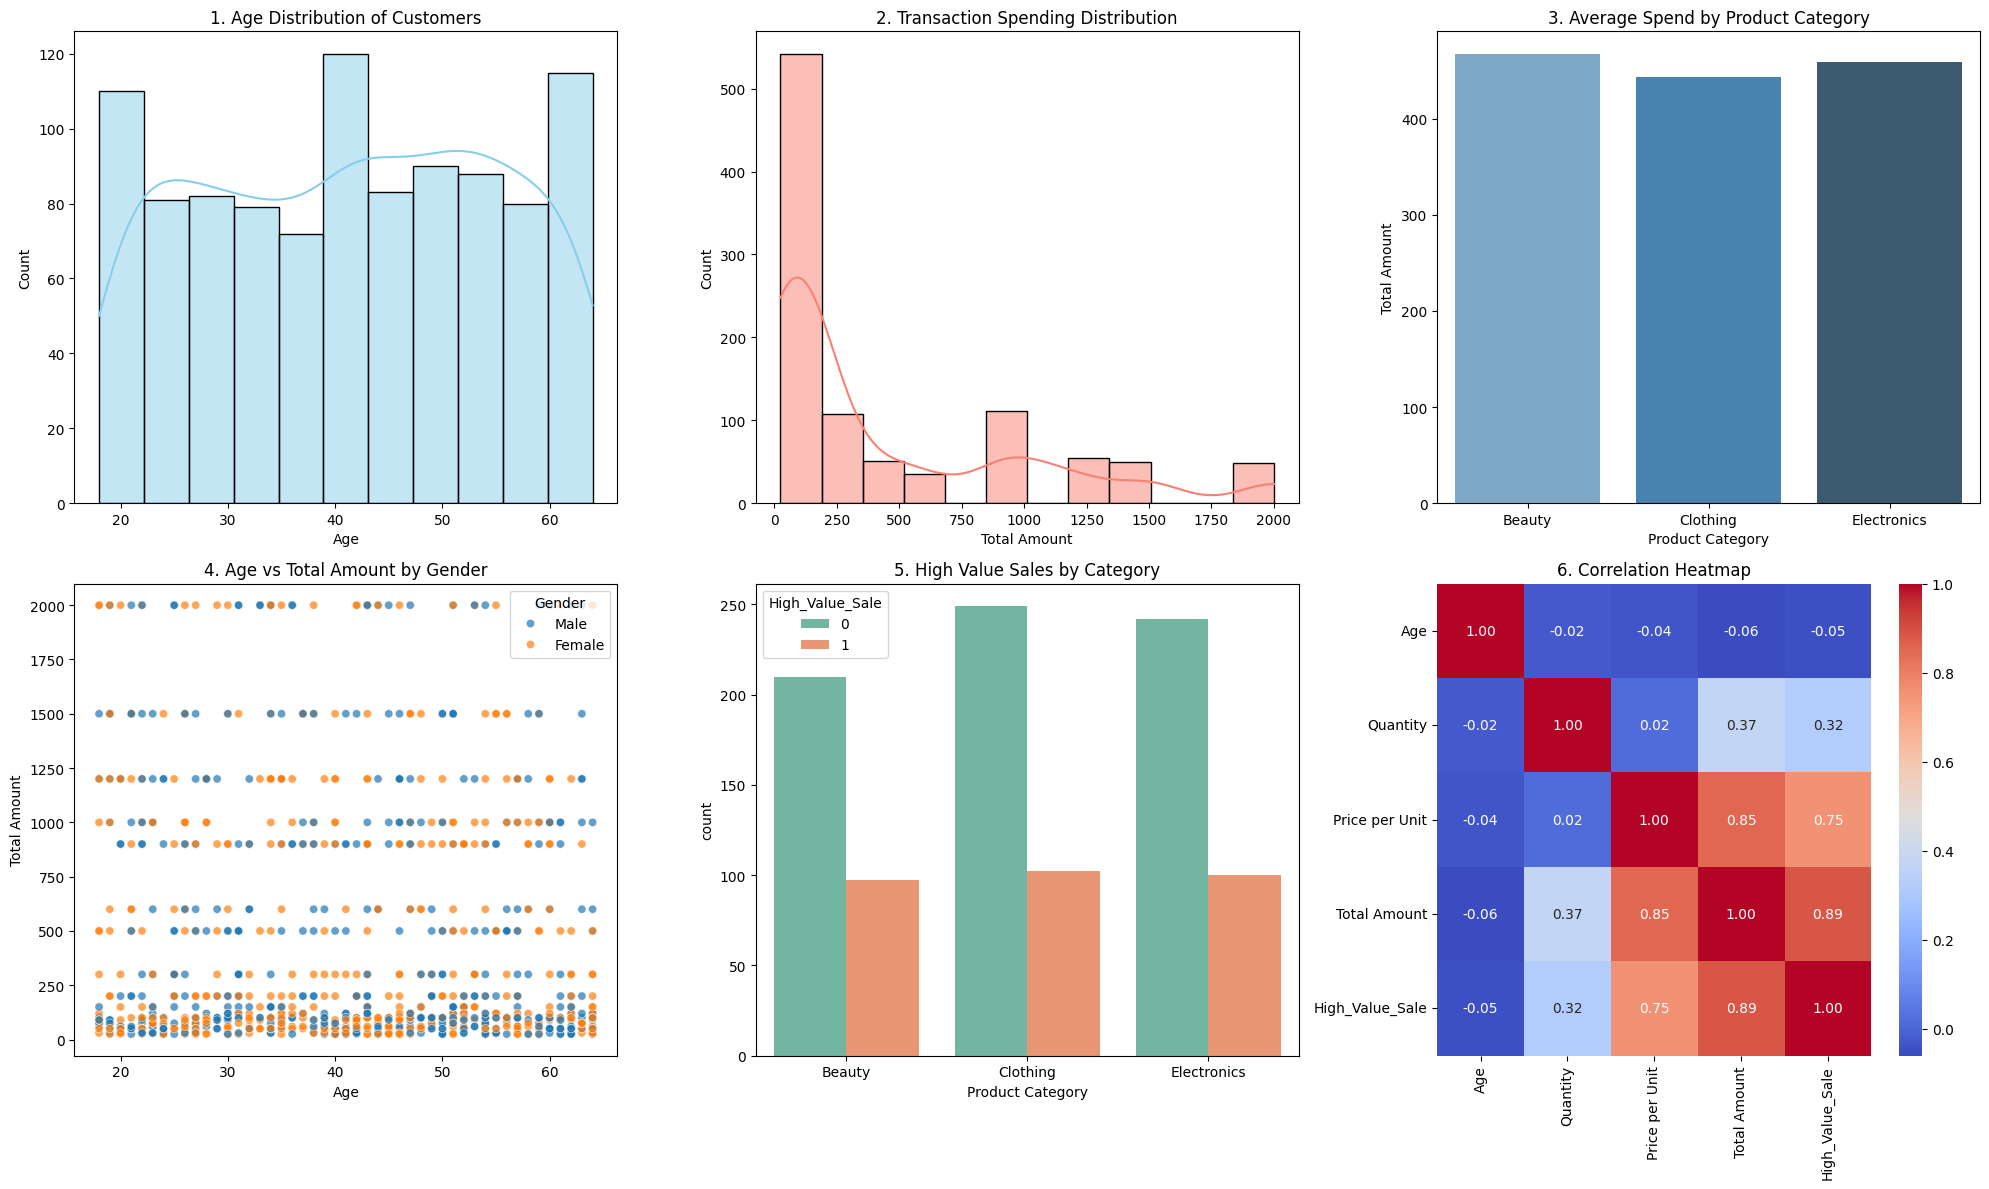

In [ ]:
plt.figure(figsize=(20, 12))

# Plot 1: Age Distribution
plt.subplot(2, 3, 1)
sns.histplot(df_cleaned["Age"], kde=True, color="skyblue")
plt.title("1. Age Distribution of Customers")

# Plot 2: Total Amount Distribution
plt.subplot(2, 3, 2)
sns.histplot(df_cleaned["Total Amount"], kde=True, color="salmon")
plt.title("2. Transaction Spending Distribution")

# Plot 3: Spending by Product Category
plt.subplot(2, 3, 3)
sns.barplot(
    data=df_cleaned,
    x="Product Category",
    y="Total Amount",
    palette="Blues_d",
    errorbar=None,
)
plt.title("3. Average Spend by Product Category")

# Plot 4: Age vs Total Amount Scatter Plot
plt.subplot(2, 3, 4)
sns.scatterplot(
    data=df_cleaned,
    x="Age",
    y="Total Amount",
    hue="Gender",
    alpha=0.7,
)
plt.title("4. Age vs Total Amount by Gender")

# Plot 5: High Value Sale Count by Product Category
plt.subplot(2, 3, 5)
sns.countplot(
    data=df_cleaned,
    x="Product Category",
    hue="High_Value_Sale",
    palette="Set2",
)
plt.title("5. High Value Sales by Category")

# Plot 6: Correlation Heatmap
plt.subplot(2, 3, 6)
numeric_df = df_cleaned.select_dtypes(include=[np.number])
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("6. Correlation Heatmap")

plt.tight_layout()
plt.show()

**SECTION 9: OUTLIER DETECTION & IQR HANDLING**

In [ ]:
Q1 = df_cleaned["Total Amount"].quantile(0.25)
Q3 = df_cleaned["Total Amount"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_cleaned[
    (df_cleaned["Total Amount"] < lower_bound)
    | (df_cleaned["Total Amount"] > upper_bound)
]
print(f"IQR for Total Amount: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}, Upper Bound: {upper_bound:.2f}")
print(f"Number of Outliers Detected: {len(outliers)}")

IQR for Total Amount: 840.00
Lower Bound: -1200.00, Upper Bound: 2160.00
Number of Outliers Detected: 0


**SECTION 10: MACHINE LEARNING FRAMING**

In [ ]:
# Defining Feature Matrix (X) and Target Variables (y_reg, y_clf)
X_raw = df_cleaned.drop(
    columns=["Total Amount", "High_Value_Sale"], errors="ignore"
)
y_reg = df_cleaned["Total Amount"]  # Target for Linear Regression
y_clf = df_cleaned["High_Value_Sale"]  # Target for Logistic Regression

print("Features used for training:", list(X_raw.columns))

Features used for training: ['Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit']


**SECTION 11: DATA TRANSFORMATION & ONE-HOT ENCODING**

In [ ]:
# Convert categorical strings (Gender, Product Category) into numeric dummy columns
X_encoded = pd.get_dummies(X_raw, drop_first=True)

print("Encoded Feature Columns:\n", list(X_encoded.columns))

Encoded Feature Columns:
 ['Age', 'Quantity', 'Price per Unit', 'Gender_Male', 'Product Category_Clothing', 'Product Category_Electronics']


**SECTION 12: TRAIN / TEST SPLIT**

In [ ]:
# Split into 80% Training set and 20% Testing set
X_train, X_test, y_train_reg, y_test_reg = train_test_split(
    X_encoded, y_reg, test_size=0.30, random_state=42
)
_, _, y_train_clf, y_test_clf = train_test_split(
    X_encoded, y_clf, test_size=0.30, random_state=42
)

print(
    f"Training Set Shape: {X_train.shape}, Testing Set Shape: {X_test.shape}"
)

Training Set Shape: (700, 6), Testing Set Shape: (300, 6)


**SECTION 13: LINEAR REGRESSION MODEL (CONTINUOUS TARGET)**

In [ ]:
lin_model = LinearRegression()
lin_model.fit(X_train, y_train_reg)

# Predictions on the training set
y_pred_train_reg = lin_model.predict(X_train)

# Evaluate training set performance
mae_train = mean_absolute_error(y_train_reg, y_pred_train_reg)
mse_train = mean_squared_error(y_train_reg, y_pred_train_reg)
r2_train = r2_score(y_train_reg, y_pred_train_reg)

# Predictions on the test set
y_pred_reg = lin_model.predict(X_test)

# Evaluate test set performance
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"--- Training Set Metrics ---")
print(f"Mean Absolute Error (MAE): {mae_train:.2f}")
print(f"Mean Squared Error (MSE): {mse_train:.2f}")
print(f"R-squared (R2) Score: {r2_train:.4f}")

print(f"\n--- Test Set Metrics ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2) Score: {r2:.4f}")

--- Training Set Metrics ---
Mean Absolute Error (MAE): 179.22
Mean Squared Error (MSE): 47680.74
R-squared (R2) Score: 0.8545

--- Test Set Metrics ---
Mean Absolute Error (MAE): 171.10
Mean Squared Error (MSE): 40664.52
R-squared (R2) Score: 0.8545


**SECTION 14: LOGISTIC REGRESSION MODEL (BINARY CLASSIFICATION)**

In [ ]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train_clf)

y_pred_clf = log_model.predict(X_test)
accuracy = accuracy_score(y_test_clf, y_pred_clf)

print(f"Model Training Accuracy: {accuracy * 100:.2f}%")

Model Training Accuracy: 95.00%


**SECTION 15: MODEL EVALUATION & CONFUSION MATRIX**

Confusion Matrix:
 [[204   7]
 [  8  81]]

Classification Report:

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       211
           1       0.92      0.91      0.92        89

    accuracy                           0.95       300
   macro avg       0.94      0.94      0.94       300
weighted avg       0.95      0.95      0.95       300



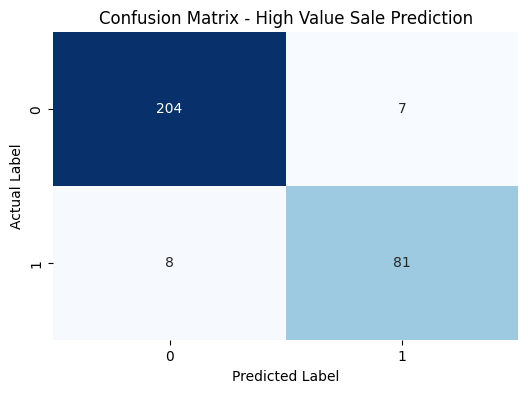

In [ ]:
cm = confusion_matrix(y_test_clf, y_pred_clf)

print("Confusion Matrix:\n", cm)
print("\nClassification Report:\n")
print(classification_report(y_test_clf, y_pred_clf))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - High Value Sale Prediction")
plt.show()

**SECTION 16: FINAL BUSINESS RECOMMENDATIONS & EXECUTIVE REPORT**

In [ ]:
print("""
==============================================================================
SECTION 16: FINAL BUSINESS RECOMMENDATIONS & EXECUTIVE REPORT
==============================================================================
1. Customer Segment Focus:
   - High-value purchases (> $500) are primarily driven by quantity and premium product
     categories like Electronics and Clothing. Marketing budgets should target
     these specific product lines.

2. Predictive Modeling Value:
   - The Logistic Regression model enables store managers to predict whether an
     incoming customer session will result in a High-Value Sale, allowing real-time
     upselling and personalized checkout incentives.

3. Inventory & Operations:
   - Age demographics show consistent purchasing across segments, suggesting store
     promotions should focus on product bundling (e.g., Electronics accessories)
     rather than aggressive age-gated discounting.
==============================================================================
""")


SECTION 16: FINAL BUSINESS RECOMMENDATIONS & EXECUTIVE REPORT
1. Customer Segment Focus:
   - High-value purchases (> $500) are primarily driven by quantity and premium product
     categories like Electronics and Clothing. Marketing budgets should target
     these specific product lines.

2. Predictive Modeling Value:
   - The Logistic Regression model enables store managers to predict whether an
     incoming customer session will result in a High-Value Sale, allowing real-time
     upselling and personalized checkout incentives.

3. Inventory & Operations:
   - Age demographics show consistent purchasing across segments, suggesting store
     promotions should focus on product bundling (e.g., Electronics accessories)
     rather than aggressive age-gated discounting.

